In [36]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from statsmodels.stats.outliers_influence import variance_inflation_factor

import warnings
warnings.filterwarnings('ignore')

# sns.set_theme(style='whitegrid', palette='Set2', font_scale=1.1)
# plt.rcParams['figure.dpi'] = 120
pd.set_option('display.max_columns', 30)

RANDOM_STATE = 42


In [37]:
train = pd.read_csv('data/train.csv')
test  = pd.read_csv('data/test.csv')

print(f'Train shape: {train.shape}')
print(f'Test  shape: {test.shape}')
train.head()

Train shape: (668665, 15)
Test  shape: (286571, 14)


,id,Age,Annual_Income_USD,Daily_Commute_km,Number_of_Cars_Owned,Charging_Stations_Near_Home,Charging_Stations_Near_Work,Environmental_Concern_Level,Gender,City_Type,Current_Car_Type,Home_Charging_Possible,Subsidy_Available,Range_Anxiety_Level,Will_Buy_EV
0,0,66,92887.0,23.4,2,3,7,1.0,Male,Suburban,Sedan,Yes,No,Low,No
1,1,38,30000.0,5.0,1,2,2,4.0,Male,Rural,SUV,Yes,No,Low,No
2,2,26,94389.0,36.8,1,8,15,5.0,Female,Urban,Sedan,No,Yes,Low,Yes
3,3,66,73580.0,23.7,2,6,9,3.0,Male,Suburban,Hatchback,Yes,No,Low,No
4,4,54,57898.0,50.8,1,2,3,3.0,Male,Suburban,Hatchback,Yes,No,Low,No


In [38]:

train.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 668665 entries, 0 to 668664
Data columns (total 15 columns):
 #   Column                       Non-Null Count   Dtype  
---  ------                       --------------   -----  
 0   id                           668665 non-null  int64  
 1   Age                          668665 non-null  int64  
 2   Annual_Income_USD            668665 non-null  float64
 3   Daily_Commute_km             668665 non-null  float64
 4   Number_of_Cars_Owned         668665 non-null  int64  
 5   Charging_Stations_Near_Home  668665 non-null  int64  
 6   Charging_Stations_Near_Work  668665 non-null  int64  
 7   Environmental_Concern_Level  668665 non-null  float64
 8   Gender                       668665 non-null  object 
 9   City_Type                    668665 non-null  object 
 10  Current_Car_Type             668665 non-null  object 
 11  Home_Charging_Possible       668665 non-null  object 
 12  Subsidy_Available            668665 non-null  object 
 13 

In [39]:

missing = train.isnull().sum()


In [40]:

dup_count = train.duplicated().sum()
print(f'Duplicate rows: {dup_count}')

Duplicate rows: 0


In [41]:

num_cols = train.select_dtypes(include='number').columns.drop('id').tolist()
cat_cols = train.select_dtypes(include='object').columns.tolist()

print(f'Numerical columns ({len(num_cols)}): {num_cols}')
print(f'Categorical columns ({len(cat_cols)}): {cat_cols}')

Numerical columns (7): ['Age', 'Annual_Income_USD', 'Daily_Commute_km', 'Number_of_Cars_Owned', 'Charging_Stations_Near_Home', 'Charging_Stations_Near_Work', 'Environmental_Concern_Level']
Categorical columns (7): ['Gender', 'City_Type', 'Current_Car_Type', 'Home_Charging_Possible', 'Subsidy_Available', 'Range_Anxiety_Level', 'Will_Buy_EV']


In [42]:

for c in cat_cols:
    print(f'{c:30s} → {train[c].nunique()} unique → {train[c].unique()}')

Gender                         → 3 unique → ['Male' 'Female' 'Other']
City_Type                      → 3 unique → ['Suburban' 'Rural' 'Urban']
Current_Car_Type               → 4 unique → ['Sedan' 'SUV' 'Hatchback' 'Truck']
Home_Charging_Possible         → 2 unique → ['Yes' 'No']
Subsidy_Available              → 2 unique → ['No' 'Yes']
Range_Anxiety_Level            → 3 unique → ['Low' 'Medium' 'High']
Will_Buy_EV                    → 2 unique → ['No' 'Yes']


In [43]:

train[num_cols].describe().T.style.background_gradient(cmap='YlGnBu')

,count,mean,std,min,25%,50%,75%,max
Age,668665.000000,47.039171,12.875448,25.000000,36.000000,47.000000,58.000000,69.000000
Annual_Income_USD,668665.000000,84769.266989,28648.029042,30000.000000,67376.000000,84880.000000,102753.000000,188549.000000
Daily_Commute_km,668665.000000,32.158298,18.730474,5.000000,17.200000,33.600000,47.400000,98.700000
Number_of_Cars_Owned,668665.000000,1.712626,0.729275,1.000000,1.000000,2.000000,2.000000,4.000000
Charging_Stations_Near_Home,668665.000000,4.960408,3.926843,0.000000,2.000000,4.000000,7.000000,14.000000
Charging_Stations_Near_Work,668665.000000,7.176314,5.186627,0.000000,3.000000,6.000000,10.000000,19.000000
Environmental_Concern_Level,668665.000000,2.935477,1.429119,1.000000,2.000000,3.000000,4.000000,5.000000


In [44]:

skew_kurt = pd.DataFrame({
    'Skewness': train[num_cols].skew(),
    'Kurtosis': train[num_cols].kurtosis()
})
skew_kurt.style.background_gradient(cmap='coolwarm', axis=0)

,Skewness,Kurtosis
Age,-0.003786,-1.174029
Annual_Income_USD,-0.013086,-0.149234
Daily_Commute_km,-0.084589,-1.060918
Number_of_Cars_Owned,0.814497,0.356101
Charging_Stations_Near_Home,0.698730,-0.482457
Charging_Stations_Near_Work,0.700188,-0.489245
Environmental_Concern_Level,0.054283,-1.325613


In [45]:

for c in cat_cols:
    print(f'\n--- {c} ---')
    vc = train[c].value_counts()
    pct = train[c].value_counts(normalize=True) * 100
    print(pd.DataFrame({'Count': vc, 'Pct(%)': pct.round(2)}))


--- Gender ---
         Count  Pct(%)
Gender                
Male    367954   55.03
Female  295427   44.18
Other     5284    0.79

--- City_Type ---
            Count  Pct(%)
City_Type                
Urban      289305   43.27
Suburban   255377   38.19
Rural      123983   18.54

--- Current_Car_Type ---
                   Count  Pct(%)
Current_Car_Type                
Sedan             303459   45.38
SUV               246545   36.87
Hatchback          79438   11.88
Truck              39223    5.87

--- Home_Charging_Possible ---
                         Count  Pct(%)
Home_Charging_Possible                
Yes                     462677   69.19
No                      205988   30.81

--- Subsidy_Available ---
                    Count  Pct(%)
Subsidy_Available                
Yes                419909    62.8
No                 248756    37.2

--- Range_Anxiety_Level ---
                      Count  Pct(%)
Range_Anxiety_Level                
Low                  603972   90.33
Medium  

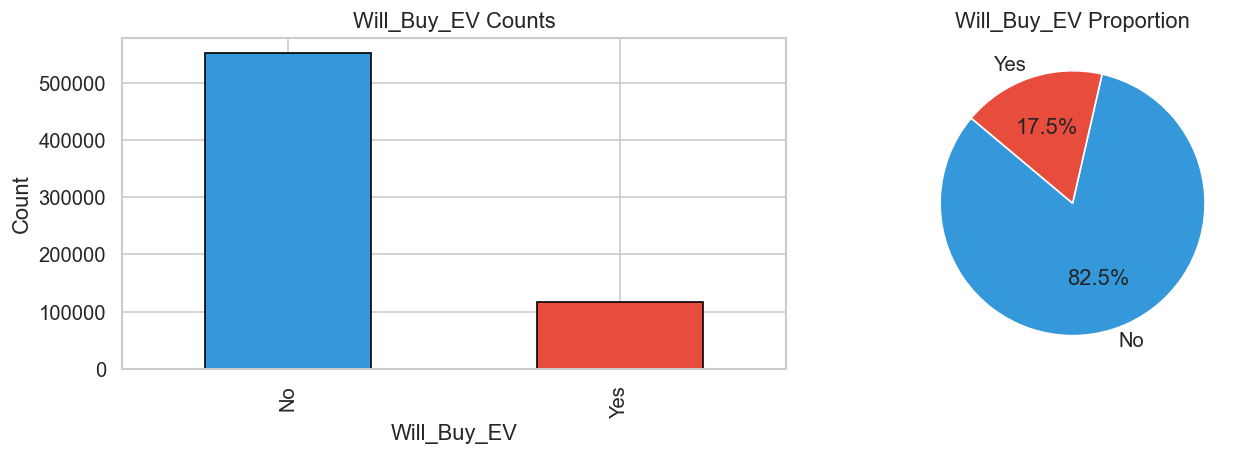

Class imbalance ratio (No:Yes) = 4.73:1


In [46]:

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

train['Will_Buy_EV'].value_counts().plot.bar(ax=axes[0], color=['#3498db', '#e74c3c'], edgecolor='k')
axes[0].set_title('Will_Buy_EV Counts')
axes[0].set_ylabel('Count')

train['Will_Buy_EV'].value_counts().plot.pie(
    autopct='%1.1f%%', startangle=140, colors=['#3498db', '#e74c3c'],
    ax=axes[1], labels=['No', 'Yes'])
axes[1].set_title('Will_Buy_EV Proportion')
axes[1].set_ylabel('')

plt.tight_layout()
plt.show()
print(f'Class imbalance ratio (No:Yes) = {train["Will_Buy_EV"].value_counts()["No"]/train["Will_Buy_EV"].value_counts()["Yes"]:.2f}:1')

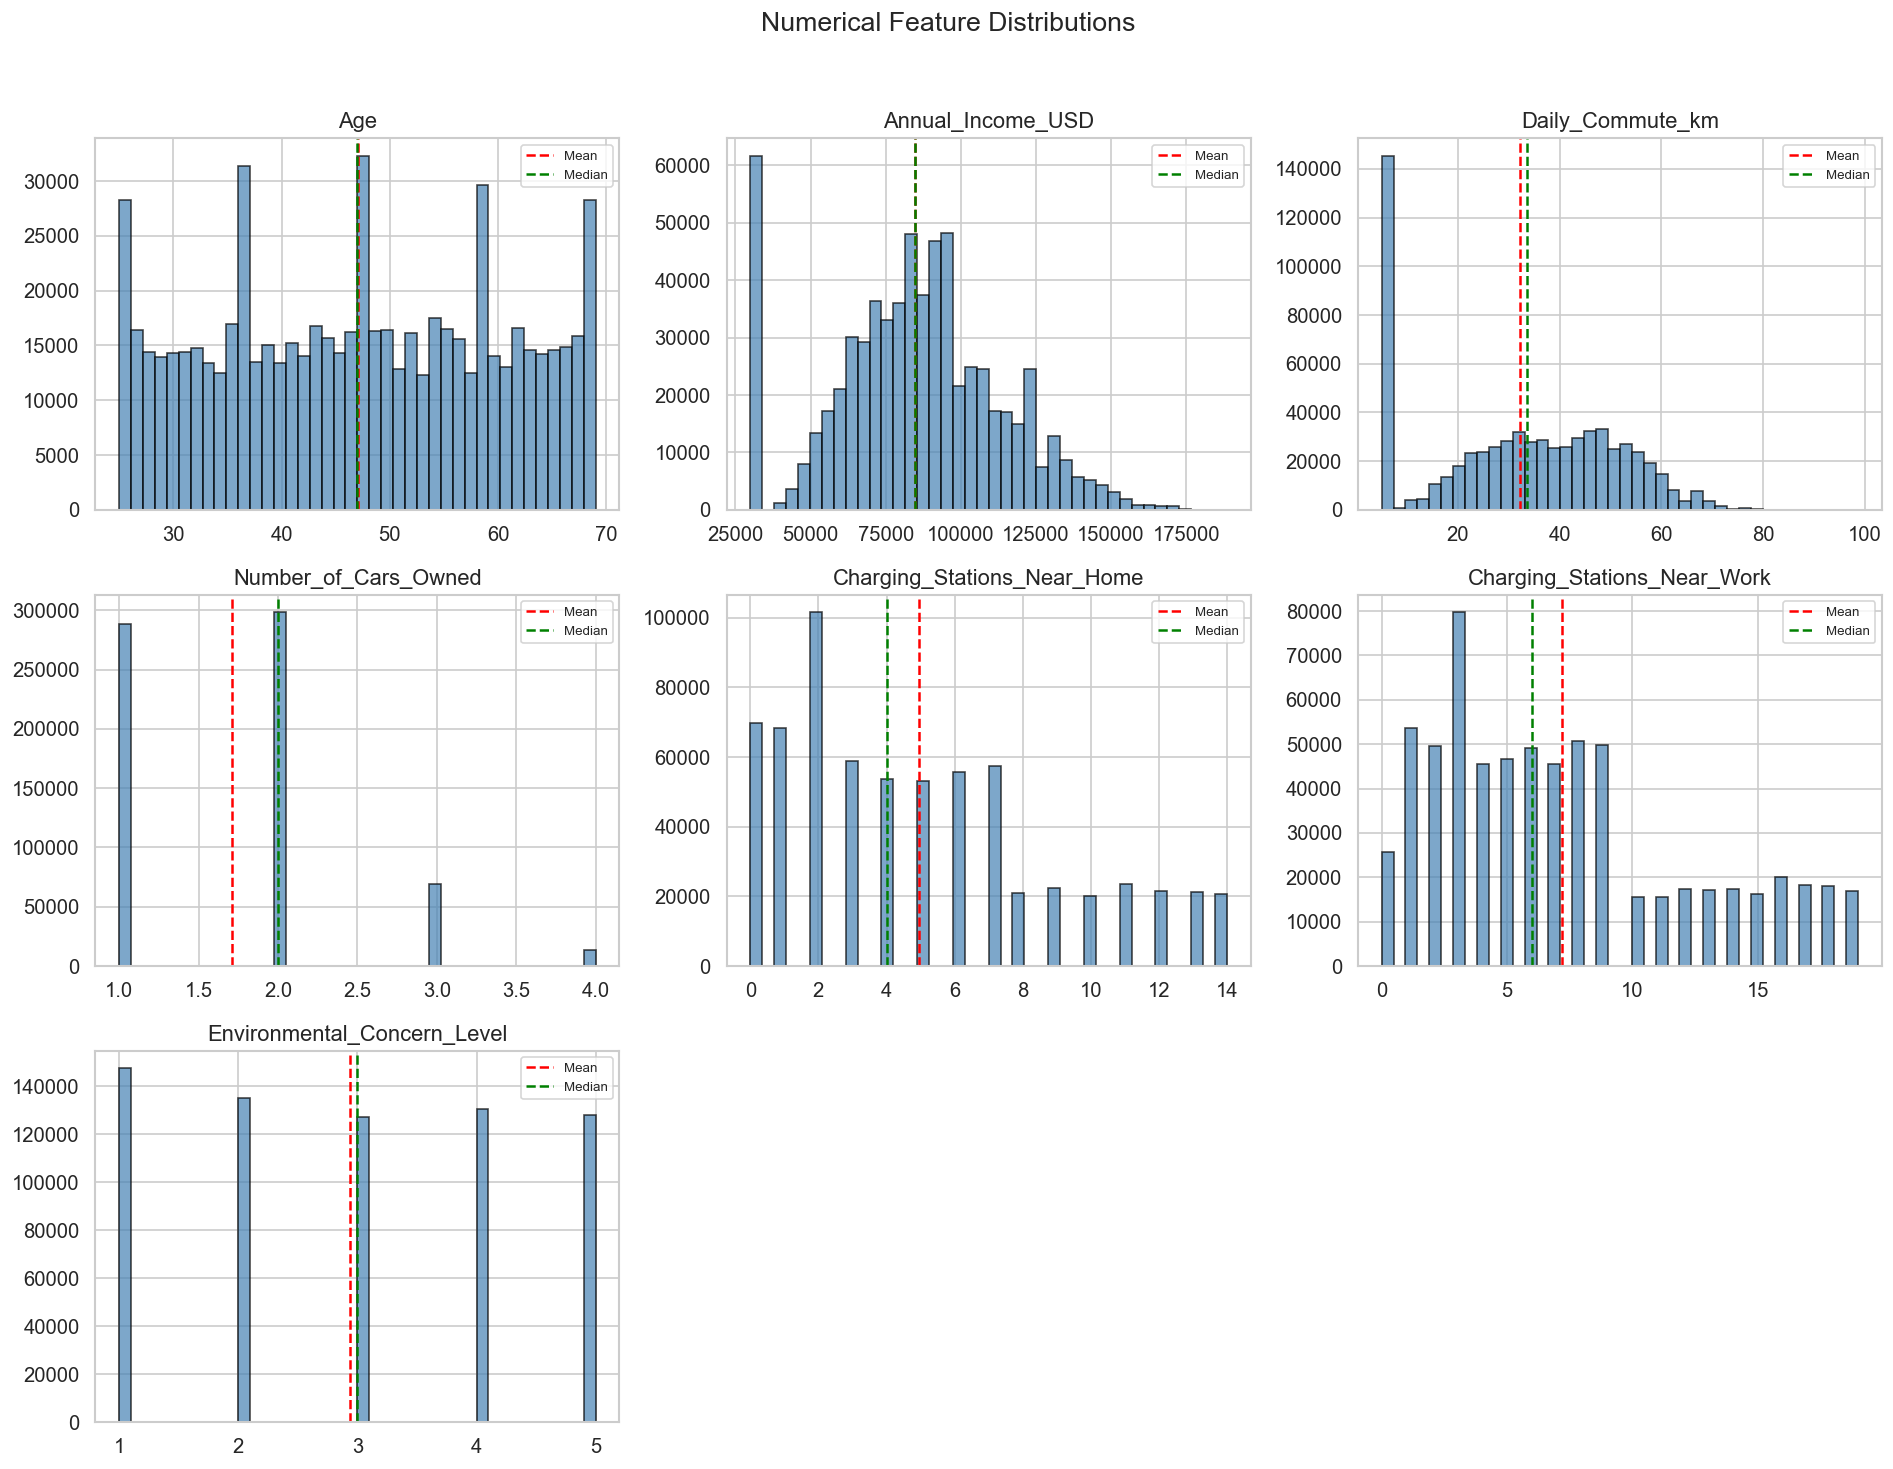

In [47]:

fig, axes = plt.subplots(3, 3, figsize=(16, 12))
axes = axes.ravel()

for i, col in enumerate(num_cols):
    if i < len(axes):
        axes[i].hist(train[col].dropna(), bins=40, edgecolor='k', alpha=0.7, color='steelblue')
        axes[i].set_title(col)
        axes[i].axvline(train[col].mean(), color='red', linestyle='--', label='Mean')
        axes[i].axvline(train[col].median(), color='green', linestyle='--', label='Median')
        axes[i].legend(fontsize=8)



for j in range(len(num_cols), len(axes)):
    axes[j].set_visible(False)

plt.suptitle('Numerical Feature Distributions', fontsize=16, y=1.02)
plt.tight_layout()
plt.show()

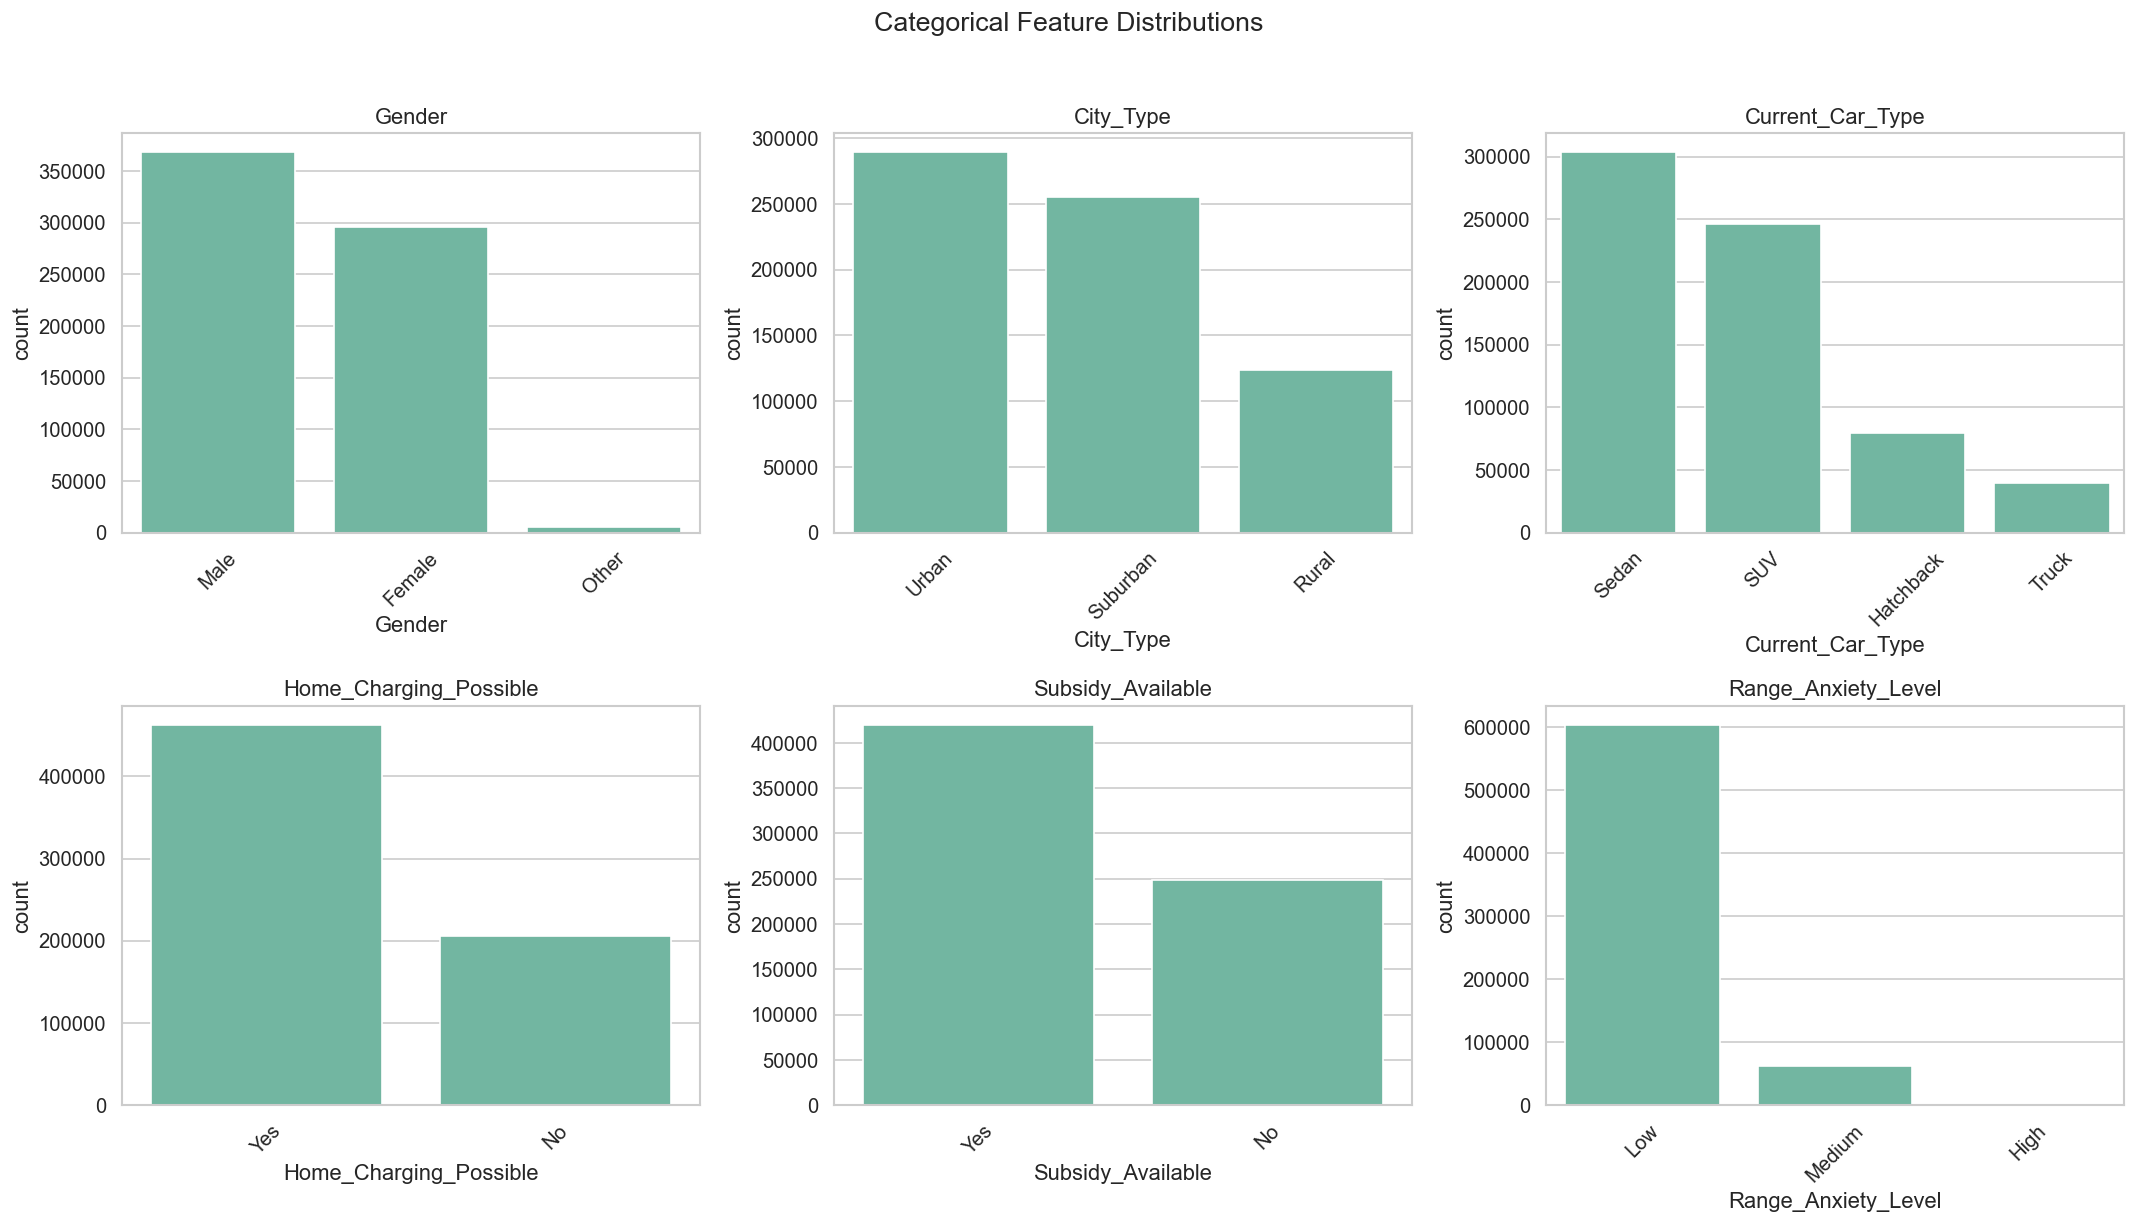

In [48]:
#
fig, axes = plt.subplots(2, 3, figsize=(18, 10))
axes = axes.ravel()

for i, col in enumerate(cat_cols):
    if i < len(axes):
        sns.countplot(data=train, x=col, ax=axes[i], order=train[col].value_counts().index)
        axes[i].set_title(col)
        axes[i].tick_params(axis='x', rotation=45)

for j in range(len(cat_cols), len(axes)):
    axes[j].set_visible(False)

plt.suptitle('Categorical Feature Distributions', fontsize=16, y=1.02)
plt.tight_layout()
plt.show()

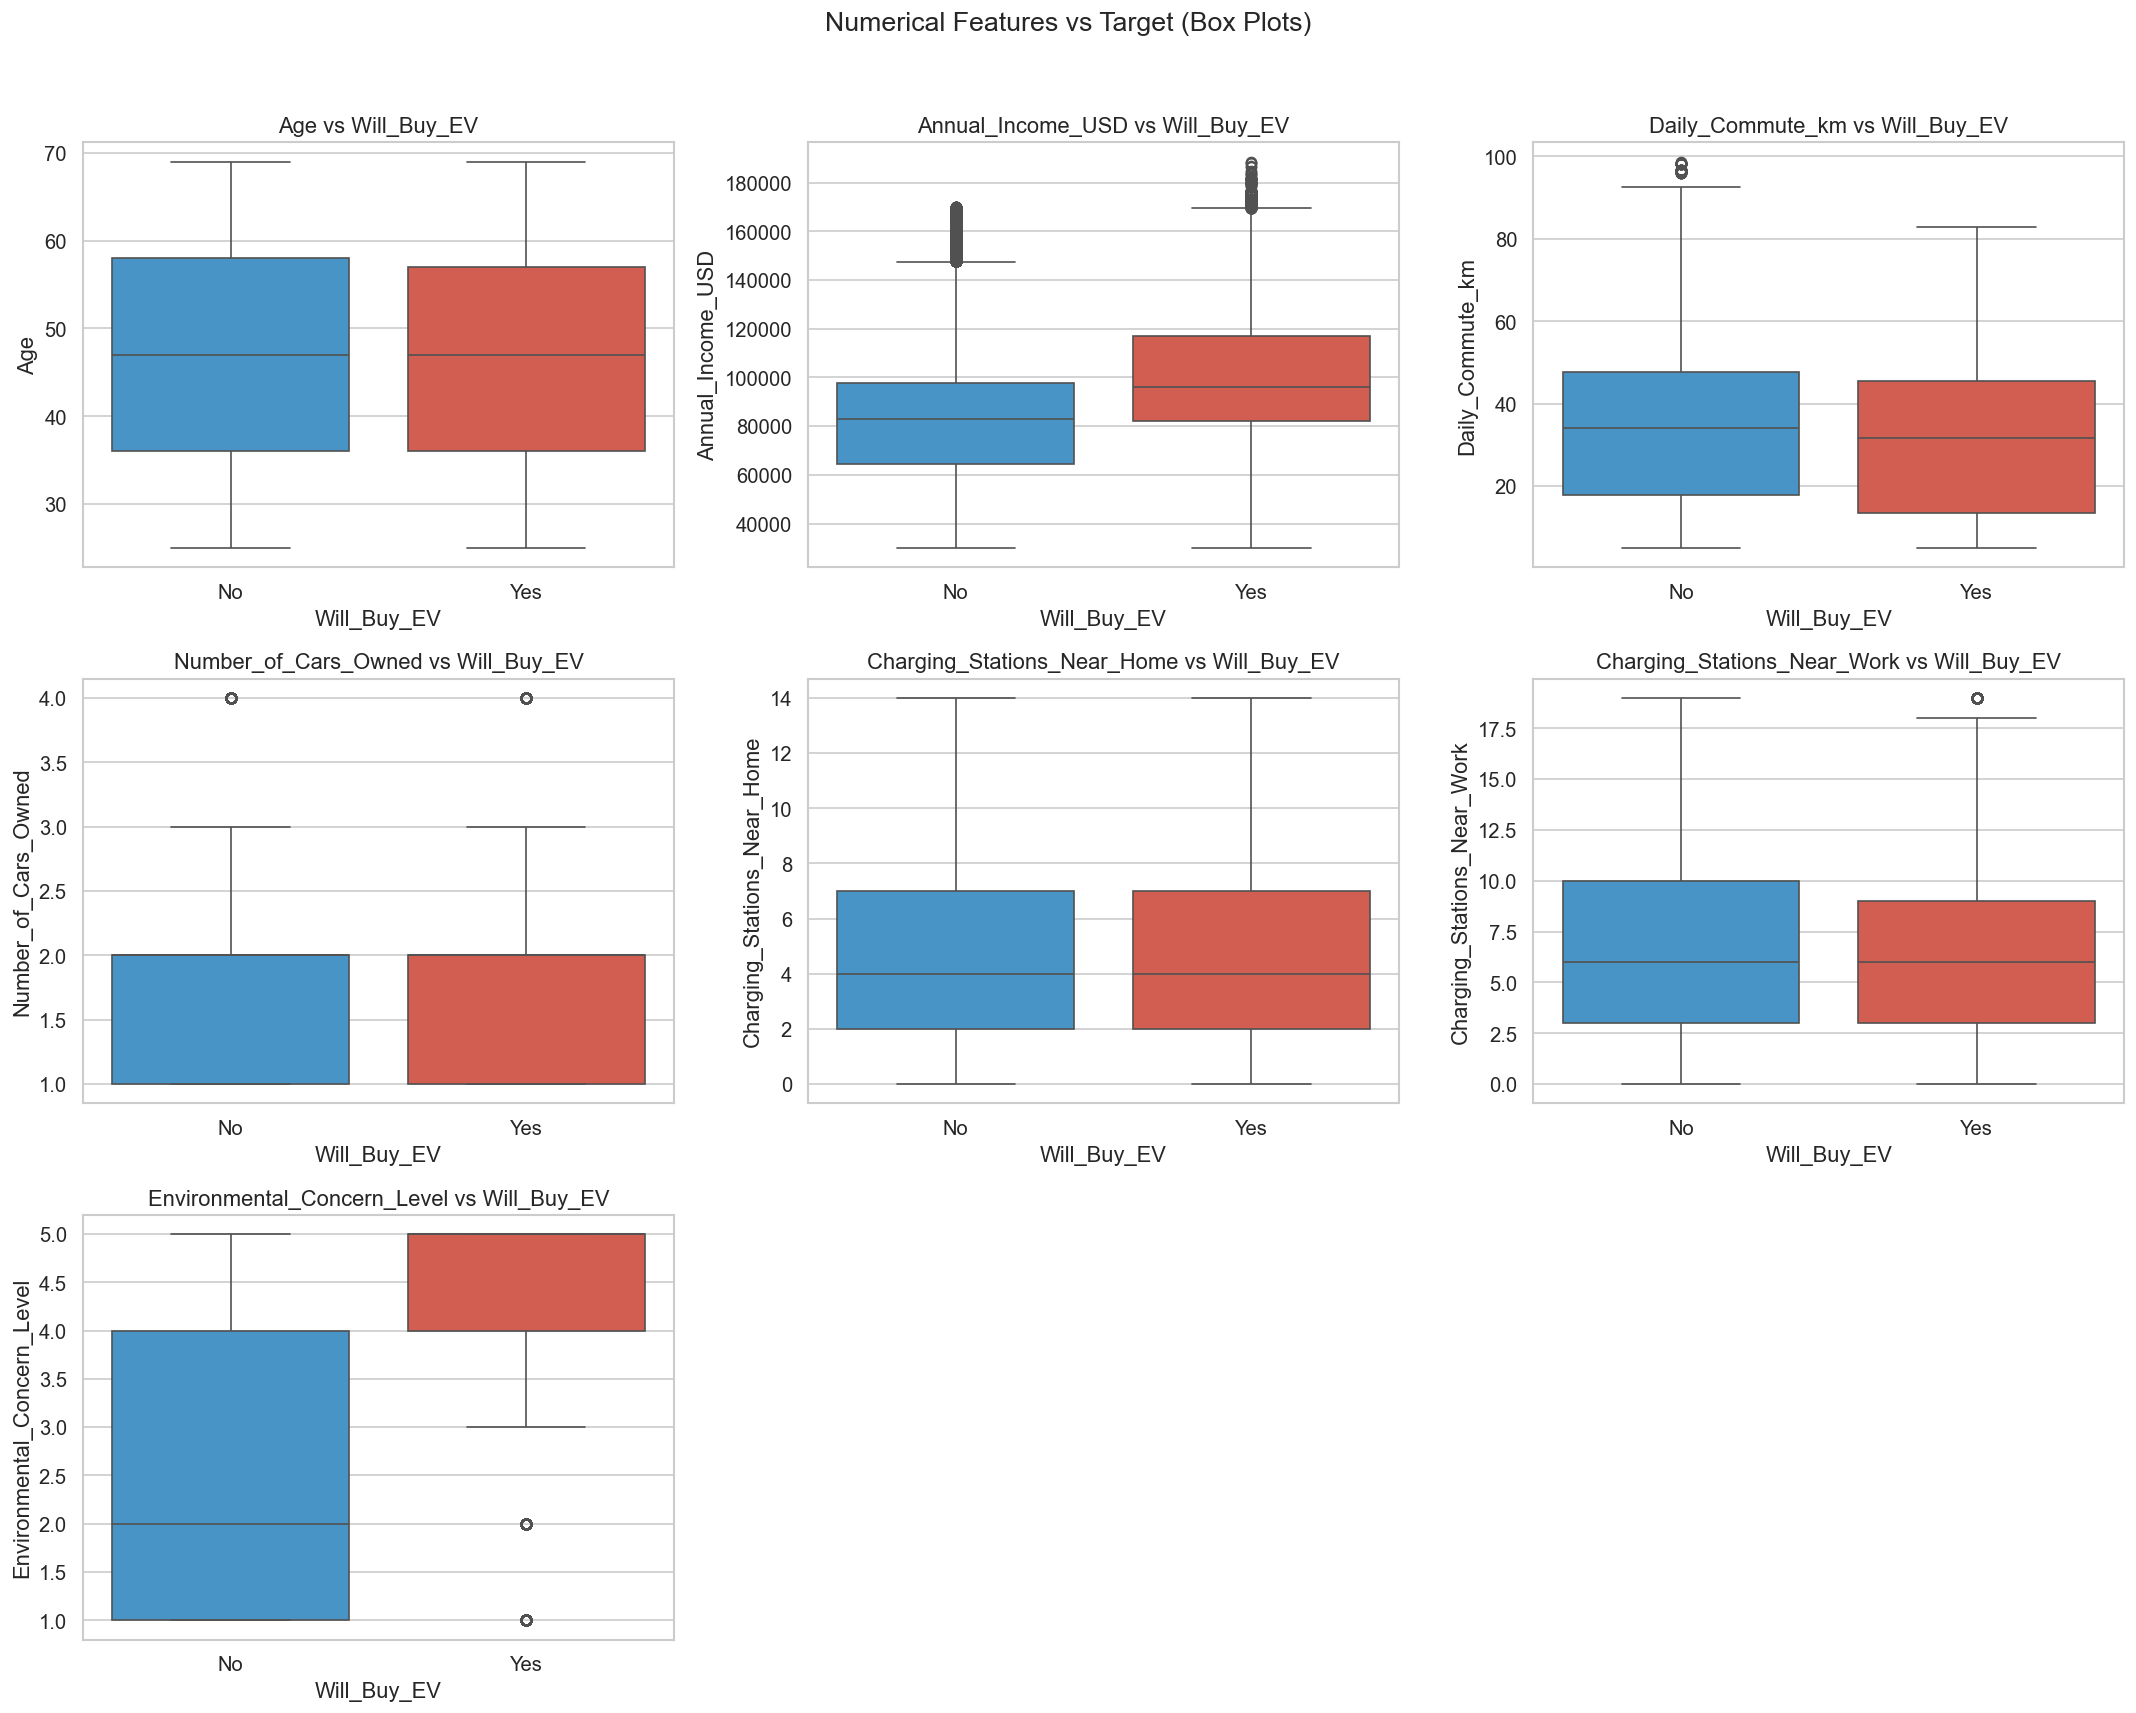

In [49]:

fig, axes = plt.subplots(3, 3, figsize=(18, 14))
axes = axes.ravel()

for i, col in enumerate(num_cols):
    if i < len(axes):
        sns.boxplot(data=train, x='Will_Buy_EV', y=col, ax=axes[i],
                    palette=['#3498db', '#e74c3c'])
        axes[i].set_title(f'{col} vs Will_Buy_EV')

for j in range(len(num_cols), len(axes)):
    axes[j].set_visible(False)

plt.suptitle('Numerical Features vs Target (Box Plots)', fontsize=16, y=1.02)
plt.tight_layout()
plt.show()

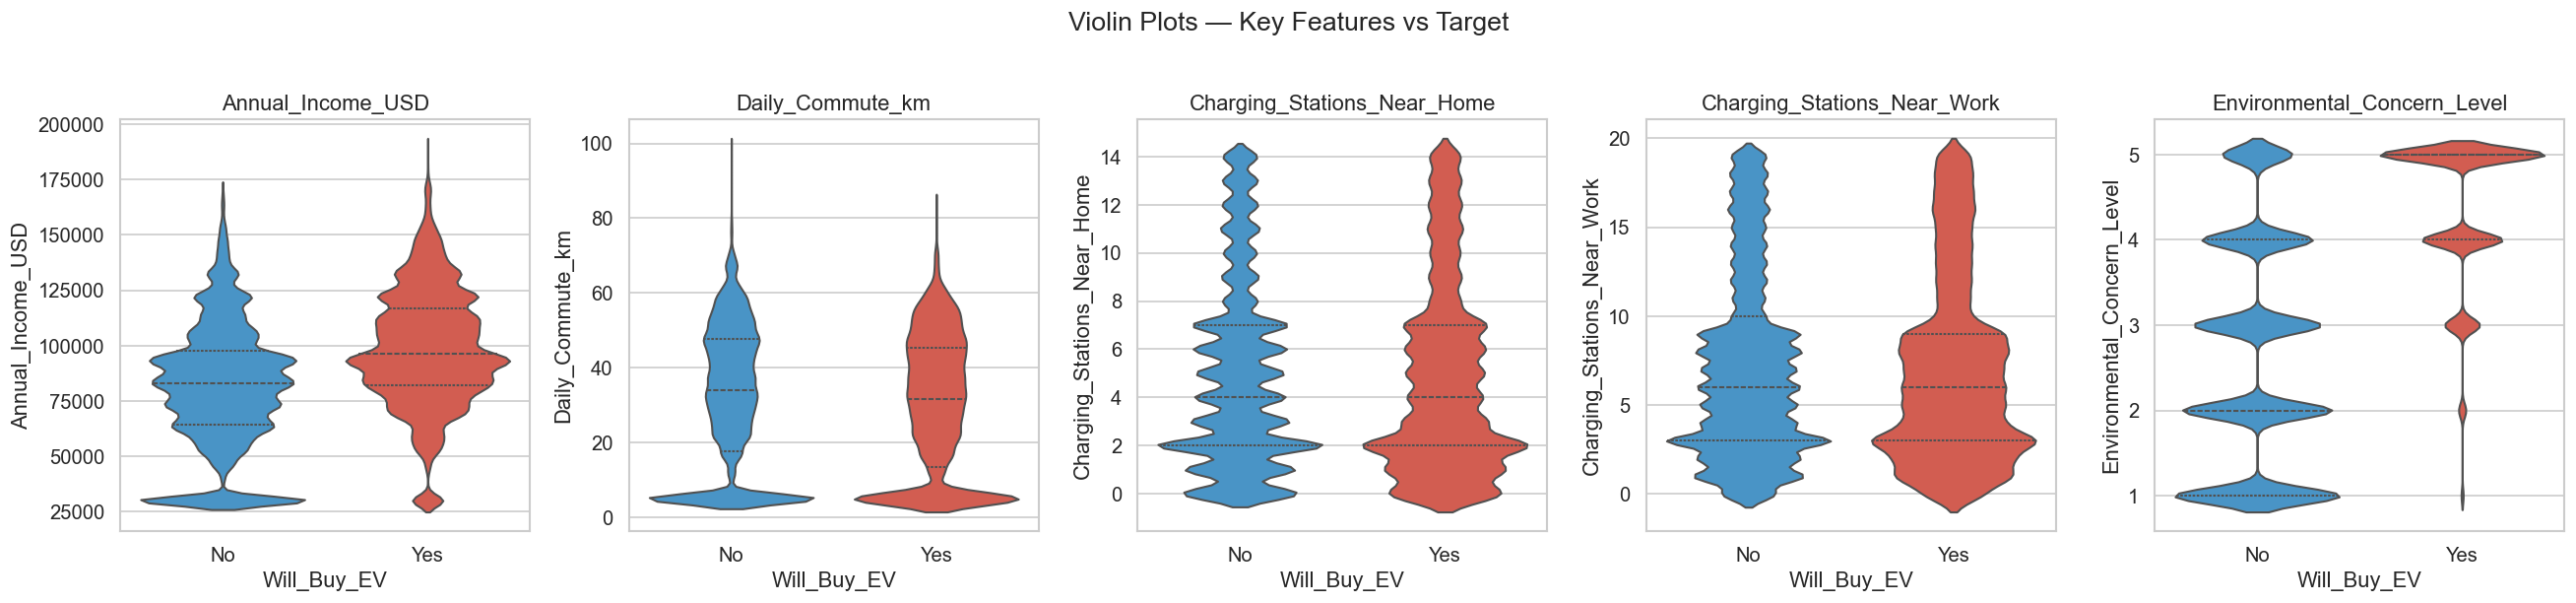

In [50]:

key_num = ['Annual_Income_USD', 'Daily_Commute_km', 'Charging_Stations_Near_Home',
           'Charging_Stations_Near_Work', 'Environmental_Concern_Level']

fig, axes = plt.subplots(1, len(key_num), figsize=(22, 5))
for i, col in enumerate(key_num):
    sns.violinplot(data=train, x='Will_Buy_EV', y=col, ax=axes[i],
                   palette=['#3498db', '#e74c3c'], inner='quartile')
    axes[i].set_title(col)

plt.suptitle('Violin Plots — Key Features vs Target', fontsize=16, y=1.02)
plt.tight_layout()
plt.show()

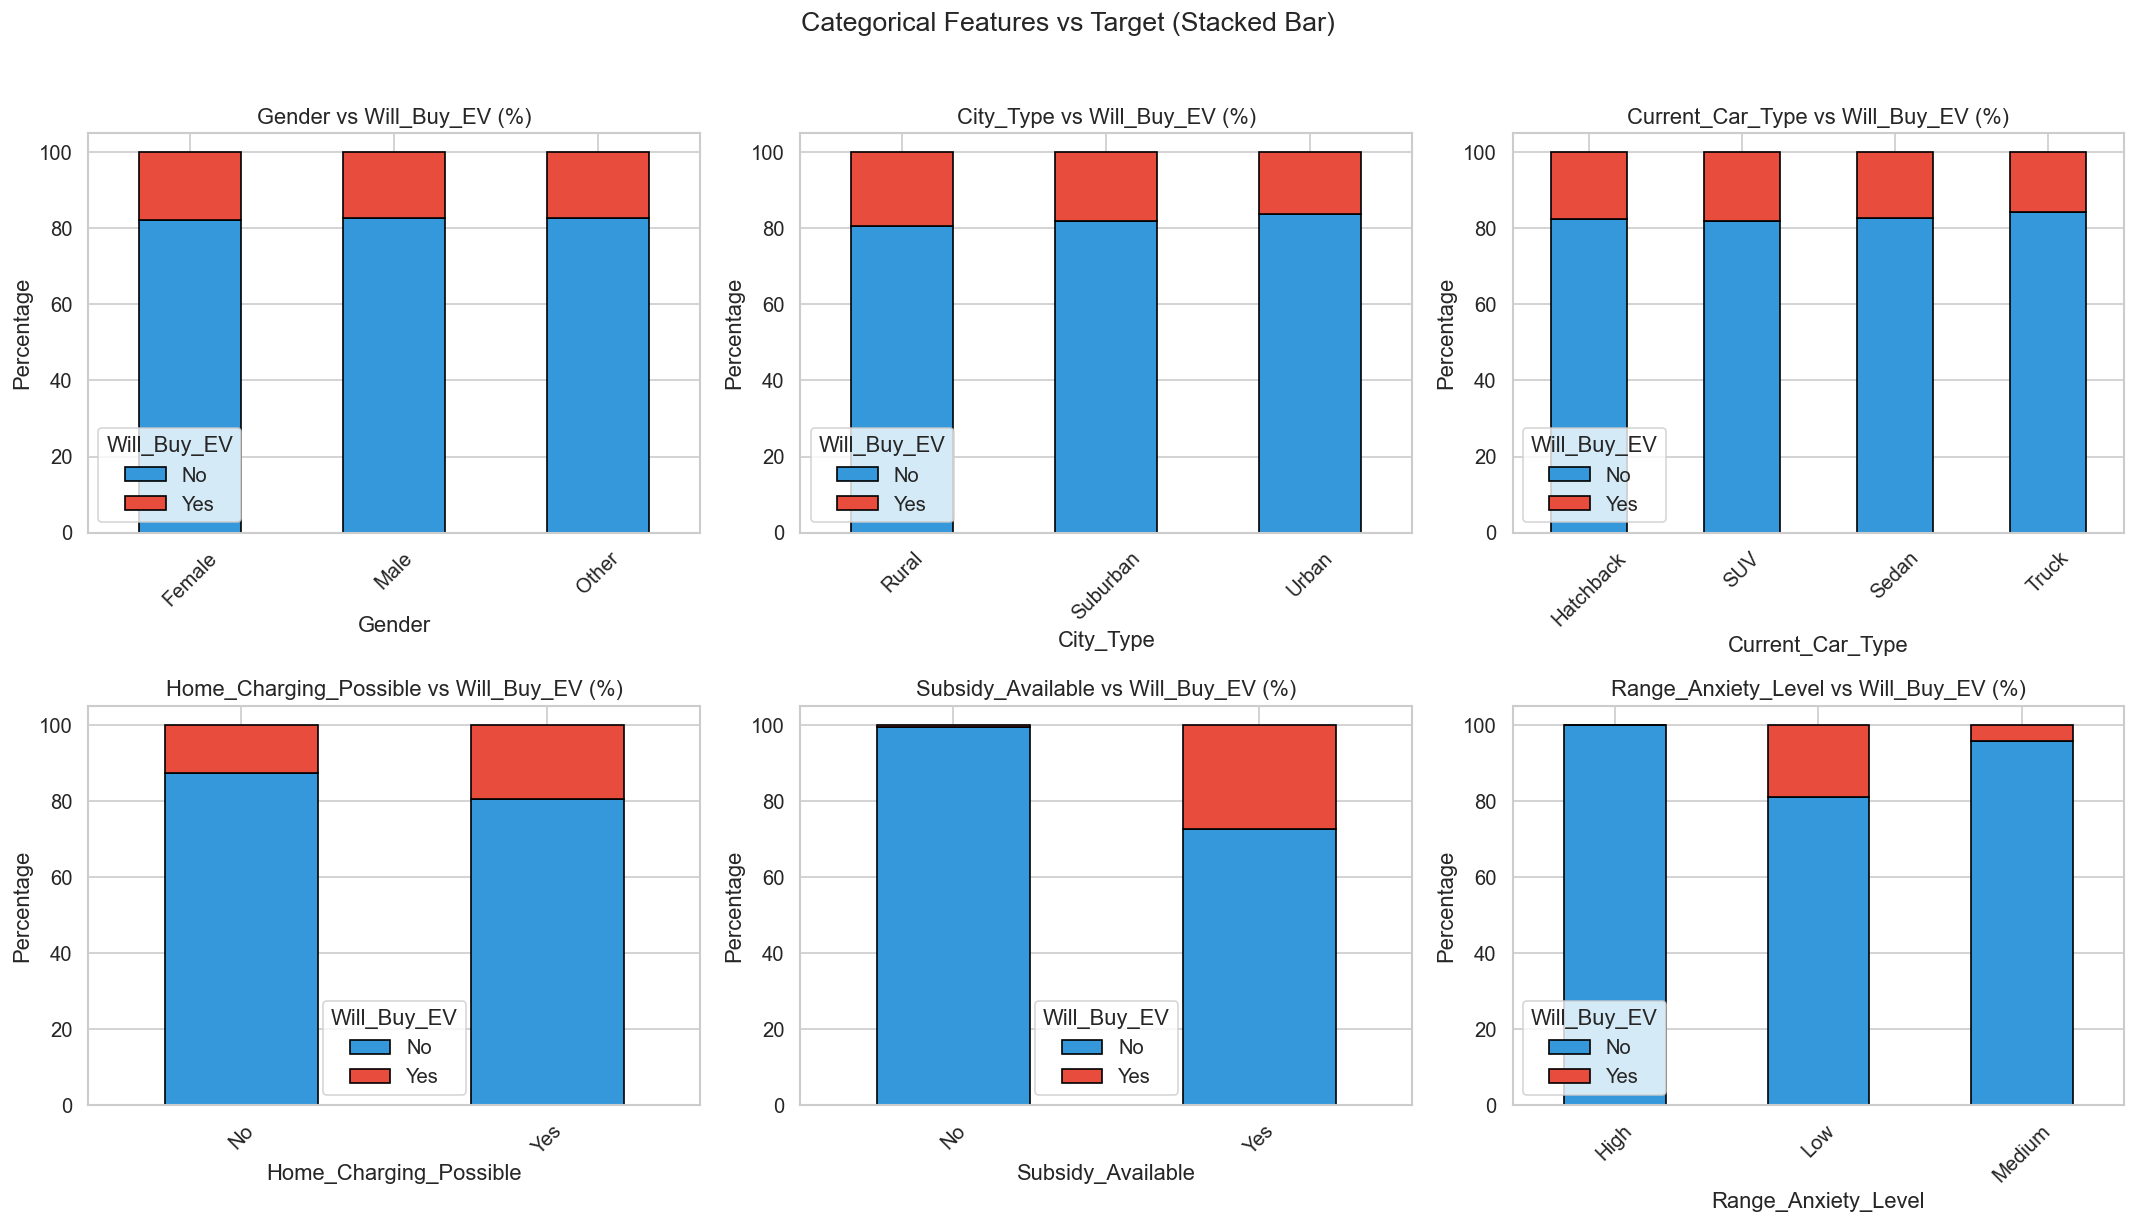

In [51]:

cat_no_target = [c for c in cat_cols if c != 'Will_Buy_EV']

fig, axes = plt.subplots(2, 3, figsize=(18, 10))
axes = axes.ravel()

for i, col in enumerate(cat_no_target):
    if i < len(axes):
        ct = pd.crosstab(train[col], train['Will_Buy_EV'], normalize='index') * 100
        ct.plot.bar(stacked=True, ax=axes[i], color=['#3498db', '#e74c3c'], edgecolor='k')
        axes[i].set_title(f'{col} vs Will_Buy_EV (%)')
        axes[i].set_ylabel('Percentage')
        axes[i].legend(title='Will_Buy_EV')
        axes[i].tick_params(axis='x', rotation=45)

for j in range(len(cat_no_target), len(axes)):
    axes[j].set_visible(False)

plt.suptitle('Categorical Features vs Target (Stacked Bar)', fontsize=16, y=1.02)
plt.tight_layout()
plt.show()

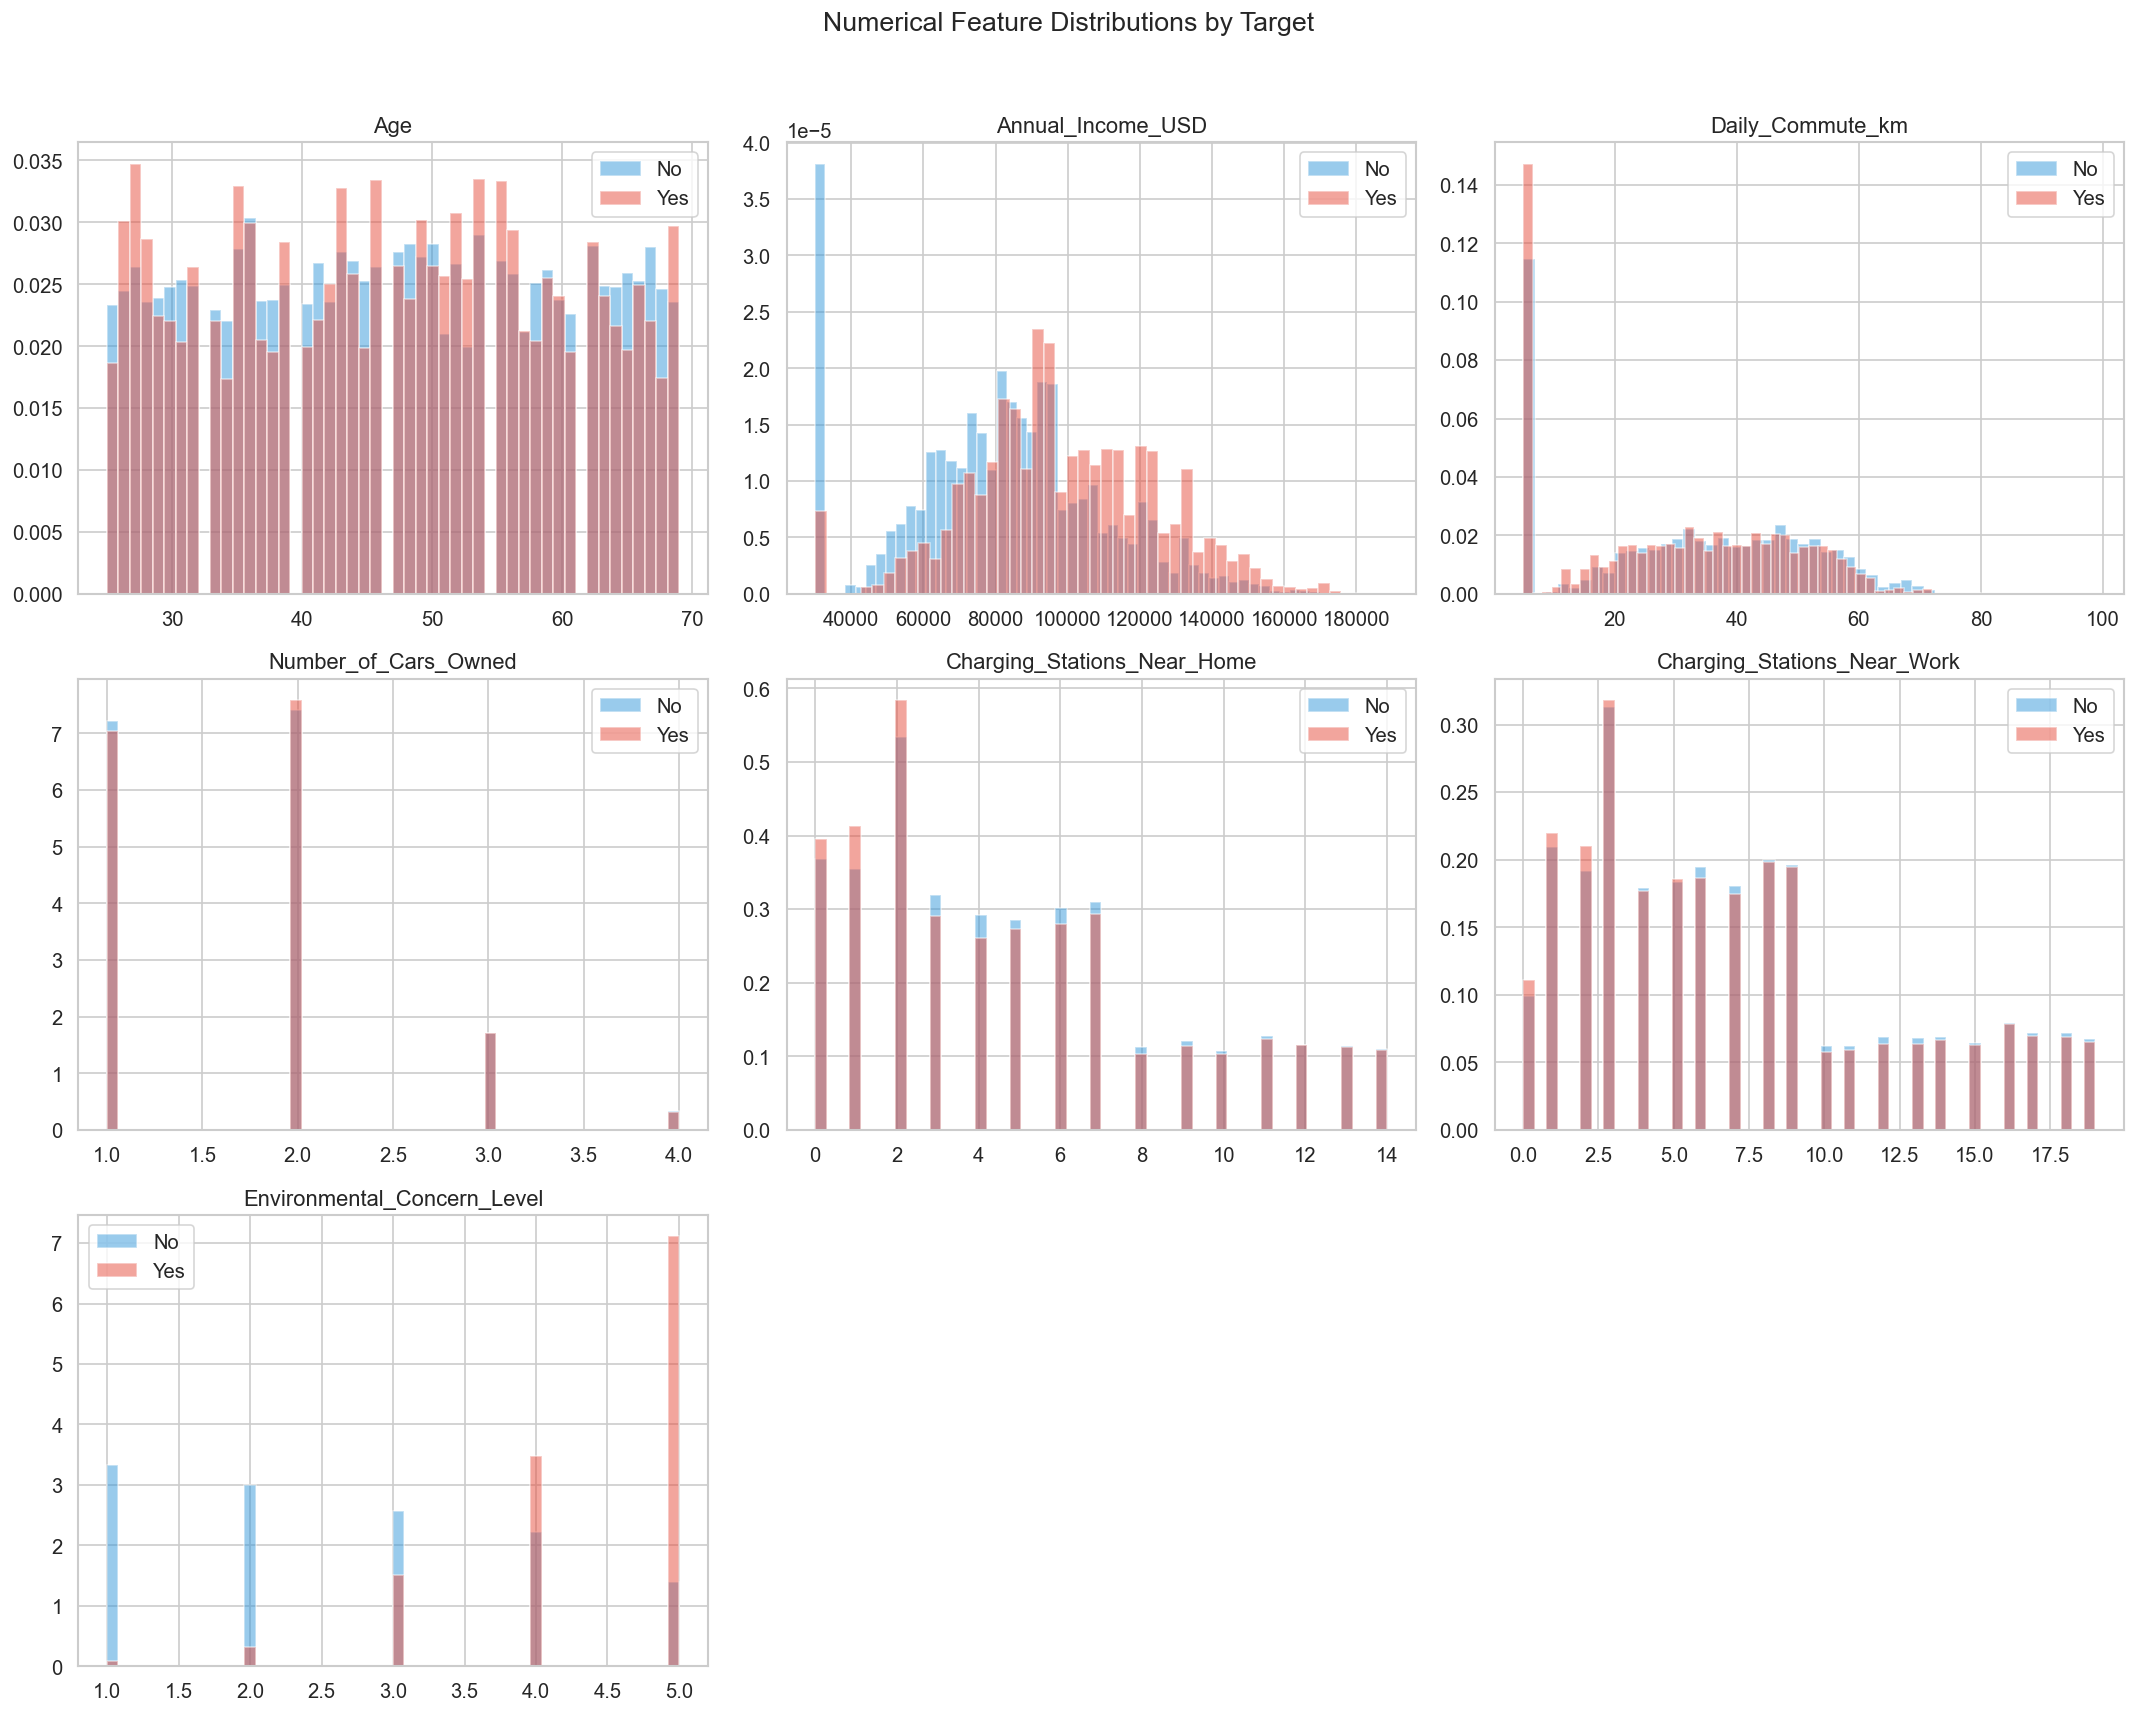

In [52]:

fig, axes = plt.subplots(3, 3, figsize=(18, 14))
axes = axes.ravel()

for i, col in enumerate(num_cols):
    if i < len(axes):
        for label, color in zip(['No', 'Yes'], ['#3498db', '#e74c3c']):
            subset = train[train['Will_Buy_EV'] == label][col].dropna()
            axes[i].hist(subset, bins=50, alpha=0.5, color=color, label=label, density=True)
        axes[i].set_title(col)
        axes[i].legend()

for j in range(len(num_cols), len(axes)):
    axes[j].set_visible(False)

plt.suptitle('Numerical Feature Distributions by Target', fontsize=16, y=1.02)
plt.tight_layout()
plt.show()

In [53]:

melted = train[num_cols + ['Will_Buy_EV']].melt(
    id_vars='Will_Buy_EV', var_name='Feature', value_name='Value'
)
melted.head(10)

,Will_Buy_EV,Feature,Value
0,No,Age,66.0
1,No,Age,38.0
2,Yes,Age,26.0
3,No,Age,66.0
4,No,Age,54.0
5,No,Age,50.0
6,Yes,Age,55.0
7,No,Age,45.0
8,No,Age,39.0
9,Yes,Age,57.0


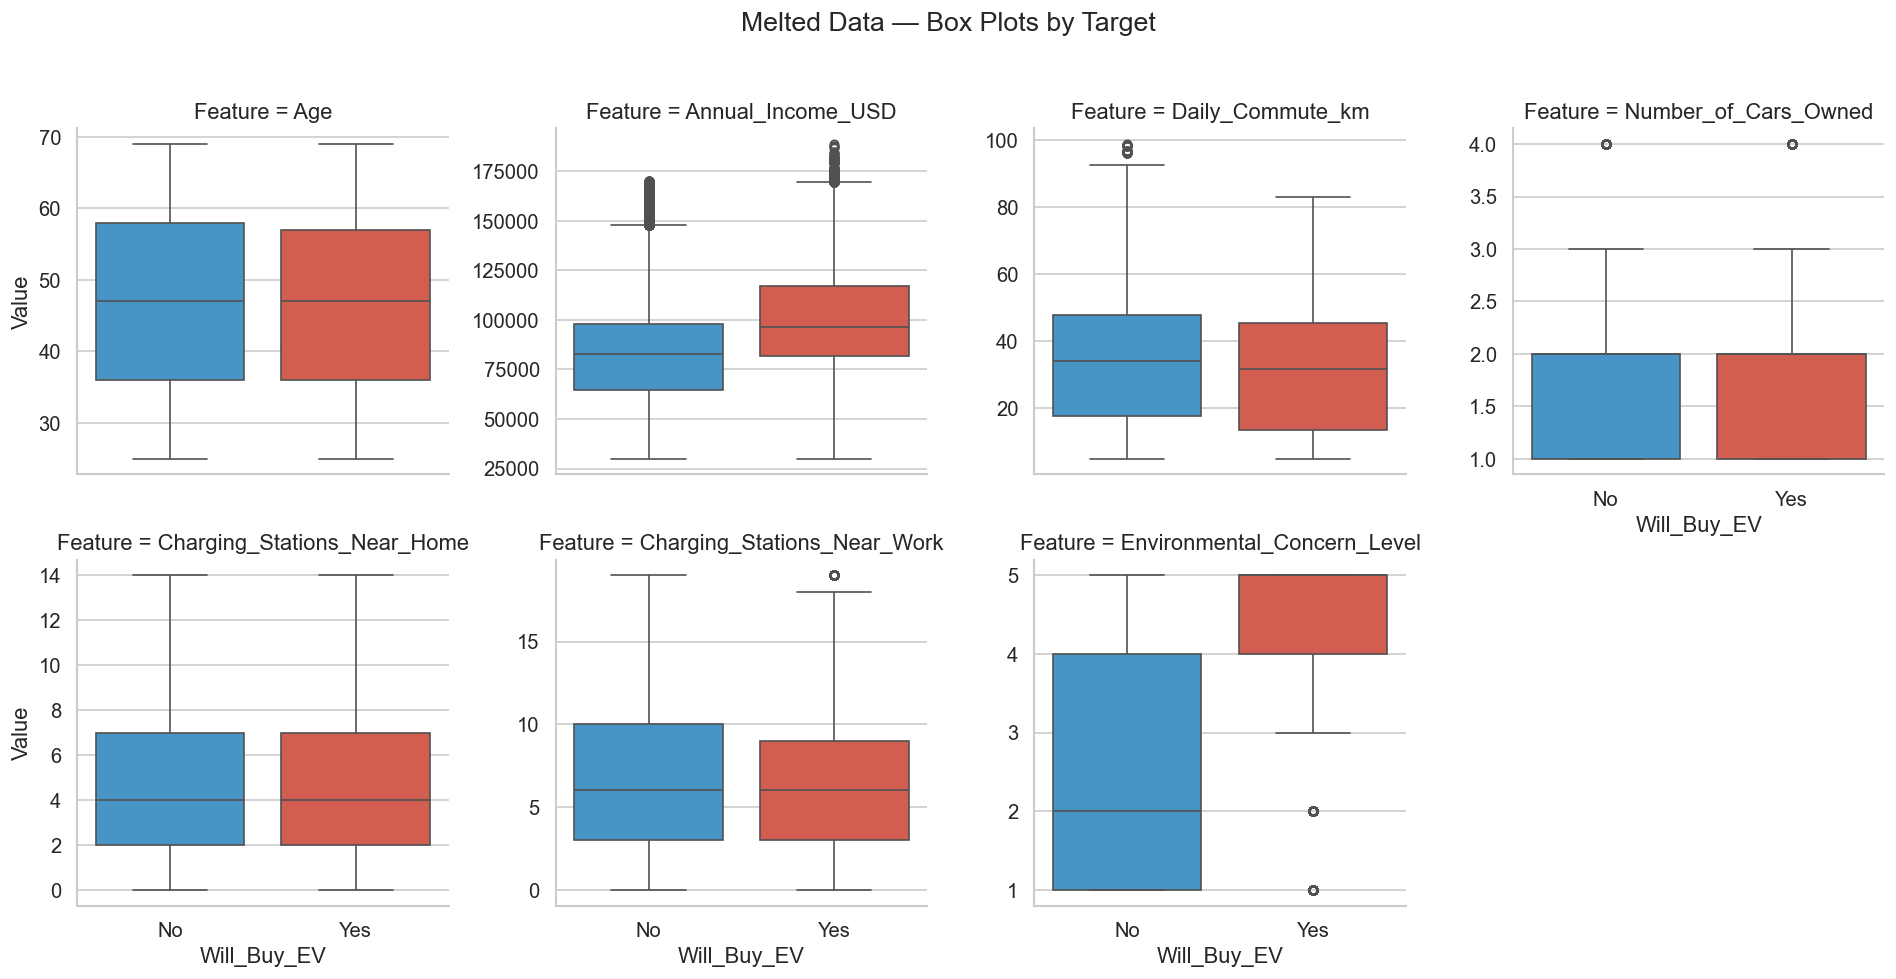

In [54]:

g = sns.catplot(
    data=melted, x='Will_Buy_EV', y='Value', col='Feature',
    kind='box', col_wrap=4, height=4, aspect=1,
    palette=['#3498db', '#e74c3c'], sharey=False
)
g.fig.suptitle('Melted Data — Box Plots by Target', y=1.02, fontsize=16)
plt.tight_layout()
plt.show()

In [55]:

pivot1 = train.pivot_table(
    values=['Annual_Income_USD', 'Daily_Commute_km', 'Charging_Stations_Near_Home',
            'Charging_Stations_Near_Work', 'Environmental_Concern_Level'],
    index='City_Type',
    columns='Will_Buy_EV',
    aggfunc='mean'
)
print('Pivot Table — Mean of features by City_Type × Will_Buy_EV:')
pivot1.style.background_gradient(cmap='YlGnBu', axis=None).format('{:.2f}')

Pivot Table — Mean of features by City_Type × Will_Buy_EV:


In [56]:

pivot2 = train.pivot_table(
    values='Annual_Income_USD',
    index='Gender',
    columns='Range_Anxiety_Level',
    aggfunc=['mean', 'median', 'count']
)
print('Pivot Table — Income stats by Gender × Range_Anxiety_Level:')
pivot2

Pivot Table — Income stats by Gender × Range_Anxiety_Level:


mean                               median  \
Range_Anxiety_Level          High           Low        Medium     High   
Gender                                                                   
Female               88234.962376  85365.268351  81258.043666  90194.5   
Male                 86402.872103  84962.282706  80858.996316  89091.0   
Other                87255.473684  85461.407275  83699.070727  94957.0   

                                      count                 
Range_Anxiety_Level      Low   Medium  High     Low Medium  
Gender                                                      
Female               85513.0  82475.0  1010  267989  26428  
Male                 84942.0  82388.0  1165  331227  35562  
Other                85132.0  85527.0    19    4756    509

In [57]:

train_temp = train.copy()
train_temp['Will_Buy_EV_num'] = train_temp['Will_Buy_EV'].map({'Yes': 1, 'No': 0})

pivot3 = train_temp.pivot_table(
    values='Will_Buy_EV_num',
    index='Current_Car_Type',
    columns='Subsidy_Available',
    aggfunc='mean'
) * 100

print('Pivot Table — EV Purchase Rate (%) by Car Type × Subsidy:')
pivot3.style.background_gradient(cmap='RdYlGn').format('{:.2f}%')

Pivot Table — EV Purchase Rate (%) by Car Type × Subsidy:


Subsidy_Available,No,Yes
Current_Car_Type,,
Hatchback,0.54%,27.27%
SUV,0.59%,28.13%
Sedan,0.57%,27.33%
Truck,0.57%,24.74%


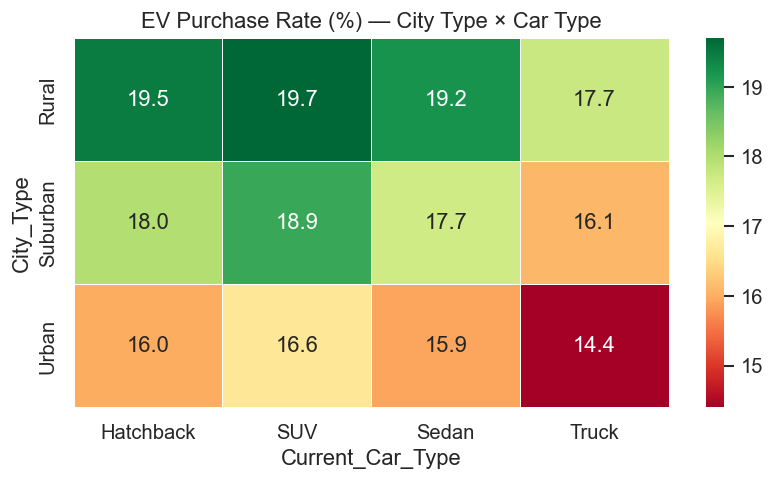

In [58]:

pivot4 = train_temp.pivot_table(
    values='Will_Buy_EV_num',
    index='City_Type',
    columns='Current_Car_Type',
    aggfunc='mean'
) * 100

plt.figure(figsize=(8, 4))
sns.heatmap(pivot4, annot=True, fmt='.1f', cmap='RdYlGn', linewidths=0.5)
plt.title('EV Purchase Rate (%) — City Type × Car Type')
plt.show()

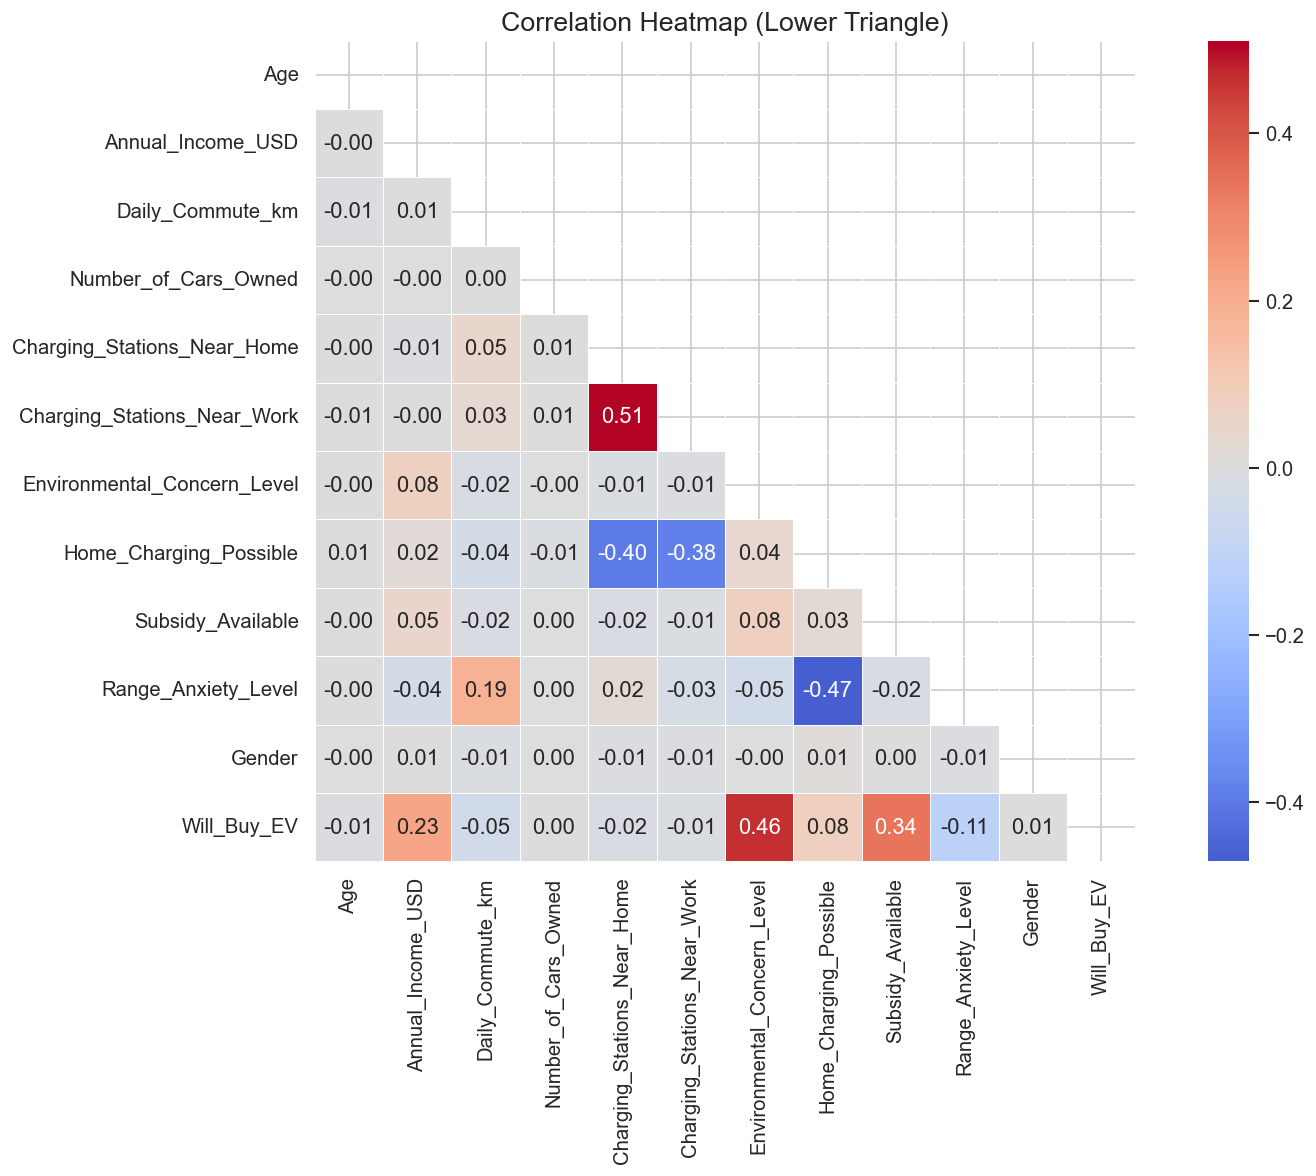

In [59]:

train_enc = train.copy()
train_enc['Will_Buy_EV'] = train_enc['Will_Buy_EV'].map({'Yes': 1, 'No': 0})
train_enc['Home_Charging_Possible'] = train_enc['Home_Charging_Possible'].map({'Yes': 1, 'No': 0})

train_enc['Subsidy_Available'] = train_enc['Subsidy_Available'].map({'Yes': 1, 'No': 0})
train_enc['Range_Anxiety_Level'] = train_enc['Range_Anxiety_Level'].map({'Low': 0, 'Medium': 1, 'High': 2})

train_enc['Gender'] = train_enc['Gender'].map({'Male': 0, 'Female': 1, 'Other': 2})

corr_cols = num_cols + ['Home_Charging_Possible', 'Subsidy_Available', 'Range_Anxiety_Level', 'Gender', 'Will_Buy_EV']
corr = train_enc[corr_cols].corr()

plt.figure(figsize=(14, 10))
mask = np.triu(np.ones_like(corr, dtype=bool))
sns.heatmap(corr, mask=mask, annot=True, fmt='.2f', cmap='coolwarm',
            center=0, linewidths=0.5, square=True)
plt.title('Correlation Heatmap (Lower Triangle)', fontsize=16)
plt.tight_layout()
plt.show()

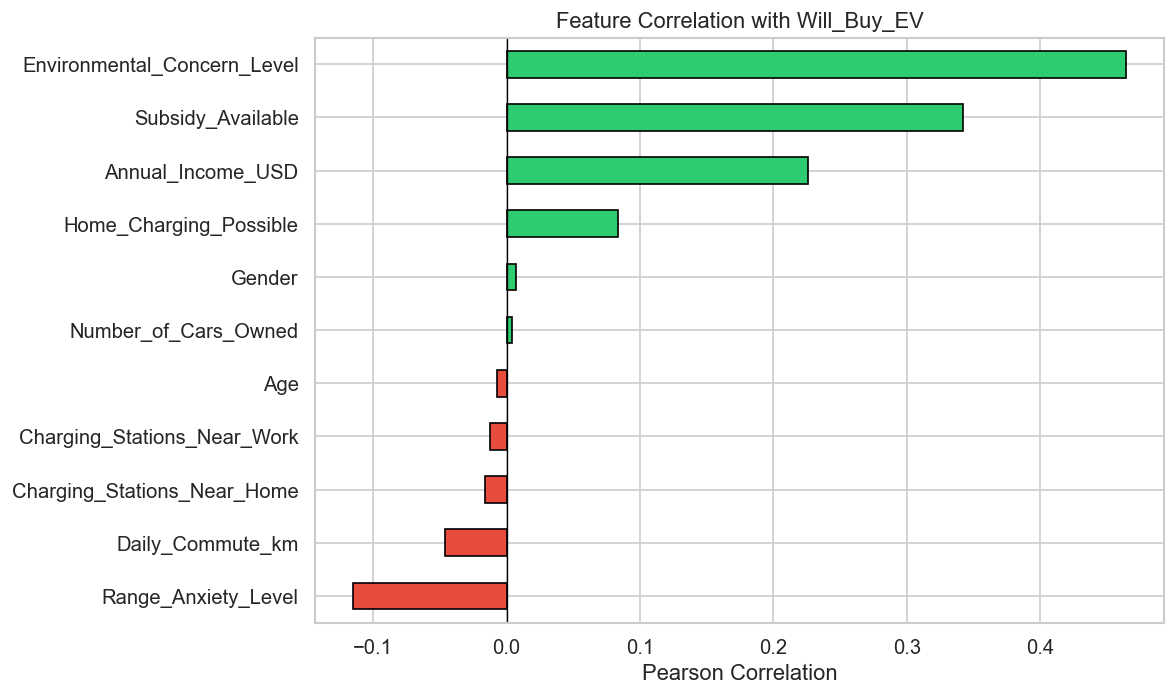

In [60]:

target_corr = corr['Will_Buy_EV'].drop('Will_Buy_EV').sort_values()

plt.figure(figsize=(10, 6))
colors = ['#e74c3c' if v < 0 else '#2ecc71' for v in target_corr.values]
target_corr.plot.barh(color=colors, edgecolor='k')
plt.title('Feature Correlation with Will_Buy_EV')
plt.xlabel('Pearson Correlation')
plt.axvline(0, color='black', linewidth=0.8)
plt.tight_layout()
plt.show()

In [61]:
def cramers_v(x, y):
    ct = pd.crosstab(x, y)
    chi2 = stats.chi2_contingency(ct)[0]
    n = ct.sum().sum()
    min_dim = min(ct.shape) - 1
    return np.sqrt(chi2 / (n * min_dim)) if min_dim > 0 else 0

chi2_results = []
for col in cat_no_target:
    ct = pd.crosstab(train[col], train['Will_Buy_EV'])
    chi2, p, dof, expected = stats.chi2_contingency(ct)
    cv = cramers_v(train[col], train['Will_Buy_EV'])
    chi2_results.append({'Feature': col, 'Chi2': chi2, 'p-value': p, 'DoF': dof, "Cramér's V": cv})

chi2_df = pd.DataFrame(chi2_results).sort_values("Cramér's V", ascending=False)
chi2_df.style.background_gradient(cmap='YlOrRd', subset=["Cramér's V"]).format({'Chi2': '{:.1f}', 'p-value': '{:.2e}', "Cramér's V": '{:.4f}'})

,Feature,Chi2,p-value,DoF,Cramér's V
4,Subsidy_Available,78382.5,0.00e+00,1,0.3424
5,Range_Anxiety_Level,8981.9,0.00e+00,2,0.1159
3,Home_Charging_Possible,4671.0,0.00e+00,1,0.0836
1,City_Type,742.8,4.97e-162,2,0.0333
2,Current_Car_Type,173.7,2.06e-37,3,0.0161
0,Gender,33.0,6.69e-08,2,0.0070


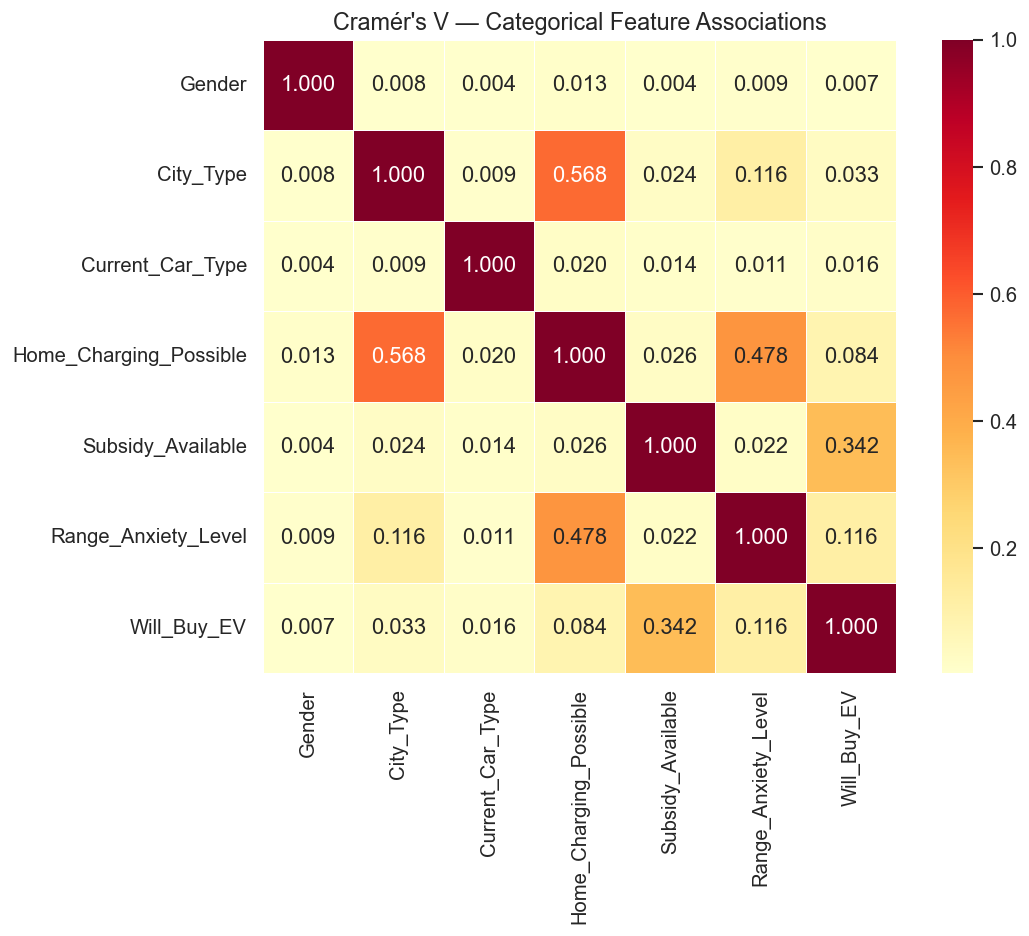

In [62]:

all_cat = cat_cols  # including target
cv_matrix = pd.DataFrame(index=all_cat, columns=all_cat, dtype=float)

for c1 in all_cat:
    for c2 in all_cat:
        cv_matrix.loc[c1, c2] = cramers_v(train[c1], train[c2])

plt.figure(figsize=(10, 8))
sns.heatmap(cv_matrix.astype(float), annot=True, fmt='.3f', cmap='YlOrRd',
            square=True, linewidths=0.5)
plt.title("Cramér's V — Categorical Feature Associations", fontsize=14)
plt.tight_layout()
plt.show()

In [63]:

city_agg = train.groupby('City_Type').agg(
    Mean_Income=('Annual_Income_USD', 'mean'),
    Median_Income=('Annual_Income_USD', 'median'),
    Mean_Commute=('Daily_Commute_km', 'mean'),
    Mean_Charging_Home=('Charging_Stations_Near_Home', 'mean'),
    Mean_Charging_Work=('Charging_Stations_Near_Work', 'mean'),
    Count=('id', 'count')
).round(2)

city_agg.style.background_gradient(cmap='Blues')

,Mean_Income,Median_Income,Mean_Commute,Mean_Charging_Home,Mean_Charging_Work,Count
City_Type,,,,,,
Rural,84713.390000,84730.000000,30.600000,1.070000,1.610000,123983
Suburban,85196.290000,85514.000000,32.230000,3.510000,5.380000,255377
Urban,84416.270000,84767.000000,32.770000,7.910000,11.150000,289305


In [64]:

car_target_agg = train.groupby(['Current_Car_Type', 'Will_Buy_EV']).agg(
    Mean_Income=('Annual_Income_USD', 'mean'),
    Mean_Env_Concern=('Environmental_Concern_Level', 'mean'),
    Count=('id', 'count')
).round(2)

car_target_agg

Mean_Income  Mean_Env_Concern   Count
Current_Car_Type Will_Buy_EV                                       
Hatchback        No              82786.46              2.63   65592
                 Yes             98959.61              4.38   13846
SUV              No              82027.40              2.64  201932
                 Yes             98364.02              4.39   44613
Sedan            No              81588.21              2.62  251274
                 Yes             99244.94              4.37   52185
Truck            No              79974.74              2.64   33088
                 Yes             98345.21              4.37    6135

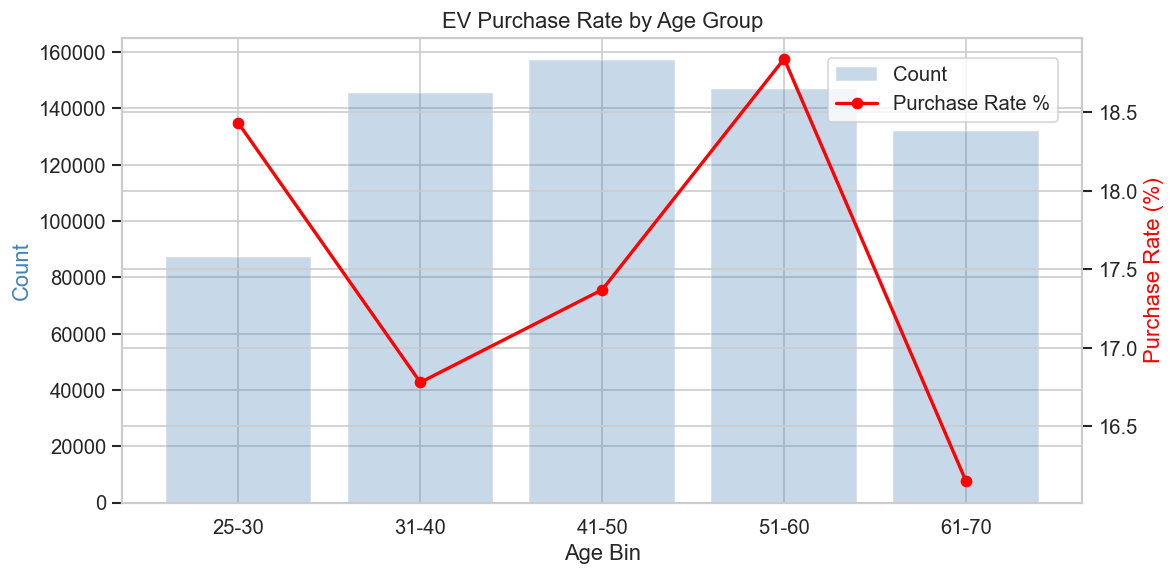

In [65]:

train_temp2 = train.copy()
train_temp2['Age_Bin'] = pd.cut(train['Age'], bins=[24, 30, 40, 50, 60, 70], labels=['25-30', '31-40', '41-50', '51-60', '61-70'])
train_temp2['Will_Buy_EV_num'] = train_temp2['Will_Buy_EV'].map({'Yes': 1, 'No': 0})

age_rate = train_temp2.groupby('Age_Bin')['Will_Buy_EV_num'].agg(['mean', 'count'])
age_rate.columns = ['Purchase_Rate', 'Count']
age_rate['Purchase_Rate'] = (age_rate['Purchase_Rate'] * 100).round(2)

fig, ax1 = plt.subplots(figsize=(10, 5))
ax2 = ax1.twinx()
ax1.bar(age_rate.index.astype(str), age_rate['Count'], alpha=0.3, color='steelblue', label='Count')
ax2.plot(age_rate.index.astype(str), age_rate['Purchase_Rate'], 'ro-', linewidth=2, label='Purchase Rate %')
ax1.set_xlabel('Age Bin')
ax1.set_ylabel('Count', color='steelblue')
ax2.set_ylabel('Purchase Rate (%)', color='red')
plt.title('EV Purchase Rate by Age Group')
fig.legend(loc='upper right', bbox_to_anchor=(0.9, 0.9))
plt.tight_layout()
plt.show()

In [66]:

from statsmodels.stats.outliers_influence import variance_inflation_factor

vif_data = train_enc[num_cols].dropna()
vif_df = pd.DataFrame({
    'Feature': num_cols,
    'VIF': [variance_inflation_factor(vif_data.values, i) for i in range(len(num_cols))]
}).sort_values('VIF', ascending=False)

vif_df.style.background_gradient(cmap='OrRd', subset=['VIF'])

,Feature,VIF
4,Charging_Stations_Near_Home,1.355224
5,Charging_Stations_Near_Work,1.353981
6,Environmental_Concern_Level,1.006371
1,Annual_Income_USD,1.006052
2,Daily_Commute_km,1.002715
0,Age,1.000113
3,Number_of_Cars_Owned,1.000106


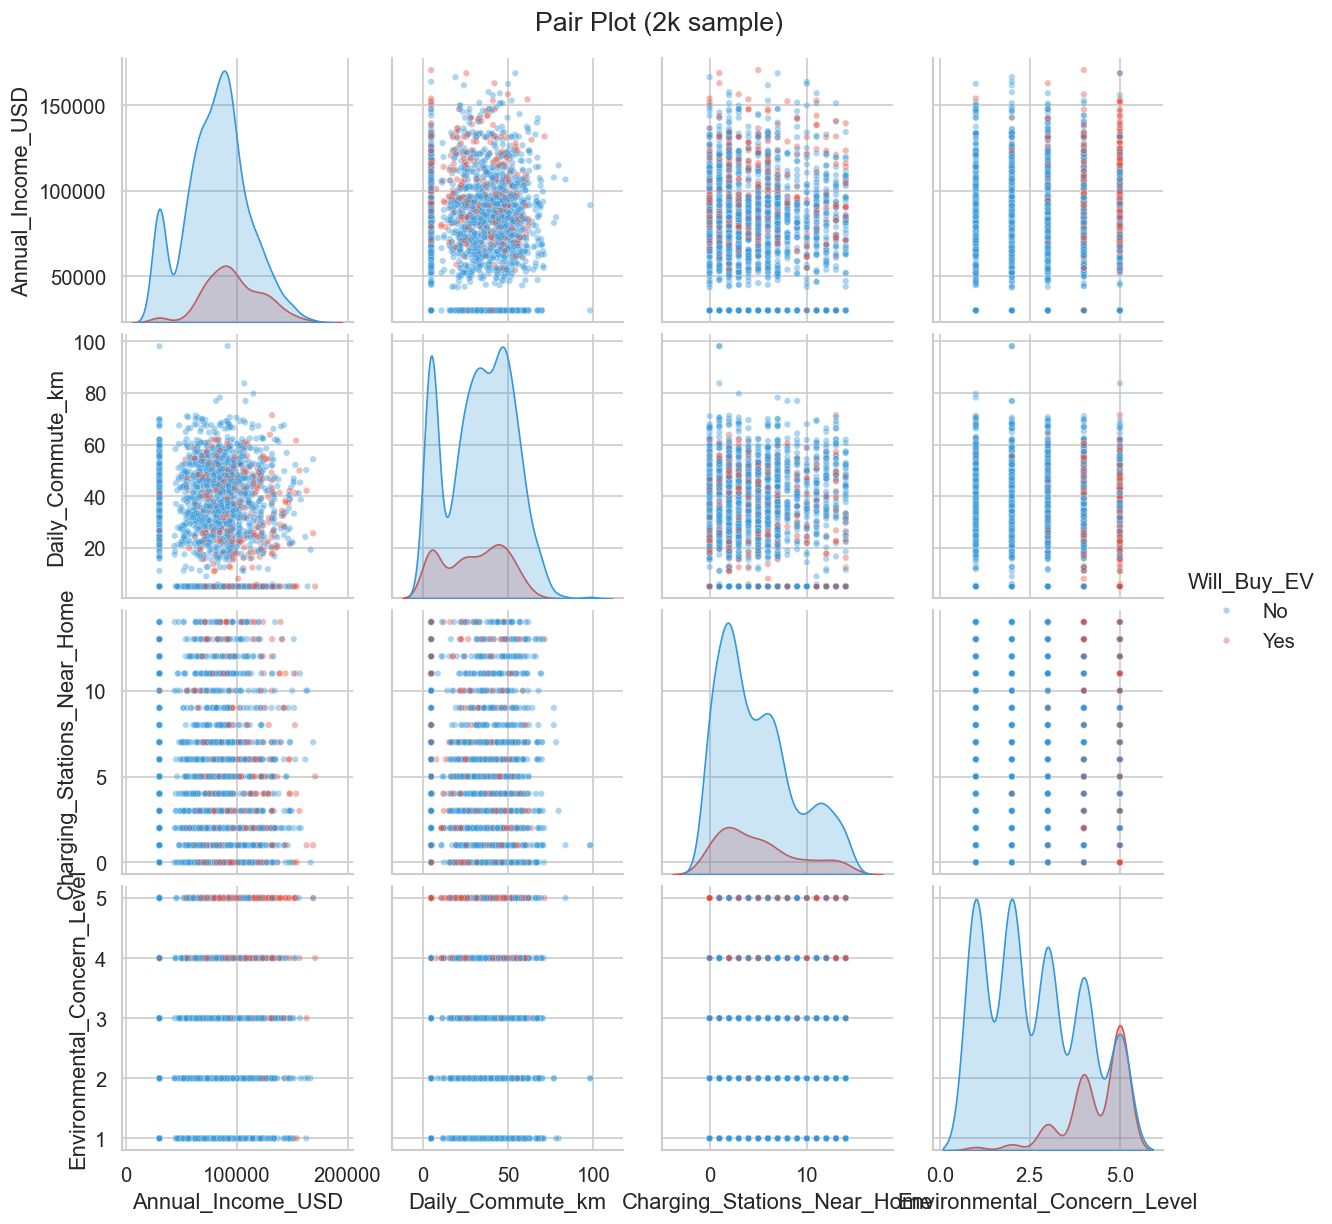

In [67]:

sample = train.sample(2000, random_state=RANDOM_STATE)
sns.pairplot(sample[['Annual_Income_USD', 'Daily_Commute_km',
                      'Charging_Stations_Near_Home', 'Environmental_Concern_Level',
                      'Will_Buy_EV']],
             hue='Will_Buy_EV', palette=['#3498db', '#e74c3c'],
             plot_kws={'alpha': 0.4, 's': 15})
plt.suptitle('Pair Plot (2k sample)', y=1.02, fontsize=16)
plt.show()